# Python Data Cleaning and Visualization - October 18, 2026 - leapit6717

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from pathlib import Path
from datetime import datetime
from IPython.display import display, Markdown

student_id = "leapit6717"

folder = Path(r"C:\Files\Excel\DA_PythonR")
file_path = folder / "AirBnBSummary_v2.xlsx"

def show_header():
    display(Markdown(
        f"### Student ID: {student_id} | "
        f"{datetime.now():%Y-%m-%d %H:%M:%S}"
    ))

def chart_title(title):
    return (
        f"{title}\nStudent ID: {student_id} | "
        f"{datetime.now():%Y-%m-%d %H:%M:%S}"
    )

# Load the original spreadsheet.
df = pd.read_excel(file_path)

show_header()

# Step 2: Remove duplicate entries.
display(Markdown("## Duplicate Rows Before Cleaning"))
display(df[df.duplicated()])

df_cleaned = df.drop_duplicates().copy()

display(Markdown("## Duplicate Rows After Cleaning"))
display(df_cleaned[df_cleaned.duplicated()])

print("Duplicate rows removed:", len(df) - len(df_cleaned))

# Step 3: Correct Private room to Private Room.
typo_count = df_cleaned["room_type"].eq("Private room").sum()

df_cleaned["room_type"] = df_cleaned["room_type"].replace(
    {"Private room": "Private Room"}
)

print("Room type entries corrected:", typo_count)

# Fill the student ID placeholder.
df_cleaned = df_cleaned.rename(
    columns={"<StudentID>": "StudentID"}
)
df_cleaned["StudentID"] = student_id

# Numerical measures used for cleaning and analysis.
columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "availability_365"
]

# Step 4: Fill missing numerical values with column medians.
display(Markdown("## Missing Values Before Filling"))
display(df_cleaned.isna().sum())

df_cleaned[columns] = df_cleaned[columns].fillna(
    df_cleaned[columns].median()
)

display(Markdown("## Missing Values After Filling"))
display(df_cleaned.isna().sum())

# Step 5: Remove rows with outliers using 1.5 × IQR.
# Listing IDs, host IDs, and student IDs are not measurements.
Q1 = df_cleaned[columns].quantile(0.25)
Q3 = df_cleaned[columns].quantile(0.75)
IQR = Q3 - Q1

outlier_rows = (
    (df_cleaned[columns] < Q1 - 1.5 * IQR)
    | (df_cleaned[columns] > Q3 + 1.5 * IQR)
).any(axis=1)

display(Markdown("## Rows Containing Outliers"))
display(df_cleaned.loc[outlier_rows, ["id"] + columns])

print("Rows removed for outliers:", int(outlier_rows.sum()))

df_cleaned = df_cleaned.loc[~outlier_rows].copy()

print("Listings remaining:", len(df_cleaned))

# Step 6: Save the cleaned spreadsheet in the same folder.
output_file = folder / "AirBnBSummary_v2_Python_Cleaned.xlsx"
df_cleaned.to_excel(output_file, index=False)

print("Cleaned spreadsheet saved to:")
print(output_file)

display(Markdown("## First 20 Cleaned Listings"))
display(df_cleaned.head(20))

### Student ID: leapit6717 | 2026-10-18 19:07:15

## Duplicate Rows Before Cleaning

,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>


## Duplicate Rows After Cleaning

,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>


...

## Rows Containing Outliers

,id,price,minimum_nights,number_of_reviews,availability_365
0,7909479,107.0,30,27,365.0
1,15966488,100.0,1,250,74.0
2,19859814,100.0,1,309,79.0
4,21712505,100.0,1,178,68.0
5,25771375,95.0,2,216,246.0
...,...,...,...,...,...
1774,920296000000000000,594.0,1,0,1.0
1775,27252097,296.0,1,164,167.0
1776,28640445,105.0,2,280,170.0
1777,620815000000000000,99.0,15,3,65.0


Rows removed for outliers: 570
Listings remaining: 1209
Cleaned spreadsheet saved to:
C:\Files\Excel\DA_PythonR\AirBnBSummary_v2_Python_Cleaned.xlsx


## First 20 Cleaned Listings

,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,StudentID
3,21071138,22992627,Joseph,Downtown,Entire home/apt,100.0,2,144,338.0,leapit6717
6,28577094,211013898,Megan,Downtown,Entire home/apt,231.0,2,88,231.0,leapit6717
7,35321049,22992627,Joseph,Downtown,Entire home/apt,112.0,2,89,219.0,leapit6717
8,36728950,4965048,Mathew,Downtown,Entire home/apt,125.0,1,77,323.0,leapit6717
9,37928558,116400313,Nate,Downtown,Entire home/apt,112.0,2,88,60.0,leapit6717
10,39165879,65045986,Jonniqua,Downtown,Entire home/apt,126.0,1,91,294.0,leapit6717
11,40952014,224493353,Dom,Downtown,Entire home/apt,177.0,2,113,317.0,leapit6717
13,42203948,224493353,Dom,Downtown,Entire home/apt,105.0,2,97,329.0,leapit6717
15,43102007,158439641,GH Hospitality,Downtown,Entire home/apt,87.0,1,85,358.0,leapit6717
16,43110099,158439641,GH Hospitality,Downtown,Entire home/apt,87.0,2,92,360.0,leapit6717


In [3]:
show_header()
display(Markdown("## Listing Statistics"))

print("Total count of listings:", len(df_cleaned))

print(
    f"Minimum price: ${df_cleaned['price'].min():.2f}"
)

print(
    f"Maximum price: ${df_cleaned['price'].max():.2f}"
)

print(
    f"Mean price of listings: ${df_cleaned['price'].mean():.2f}"
)

print(
    "Median of number_of_reviews:",
    df_cleaned["number_of_reviews"].median()
)

print(
    "Mode of minimum_nights:",
    df_cleaned["minimum_nights"].mode().tolist()
)

print(
    f"Standard deviation of price: "
    f"${df_cleaned['price'].std():.2f}"
)

correlation = df_cleaned["price"].corr(
    df_cleaned["availability_365"]
)

print(
    f"Correlation between price and availability_365: "
    f"{correlation:.4f}"
)

### Student ID: leapit6717 | 2026-10-18 19:11:53

## Listing Statistics

Total count of listings: 1209
Minimum price: $32.00
Maximum price: $308.00
Mean price of listings: $132.22
Median of number_of_reviews: 20.0
Mode of minimum_nights: [1]
Standard deviation of price: $62.53
Correlation between price and availability_365: 0.0945


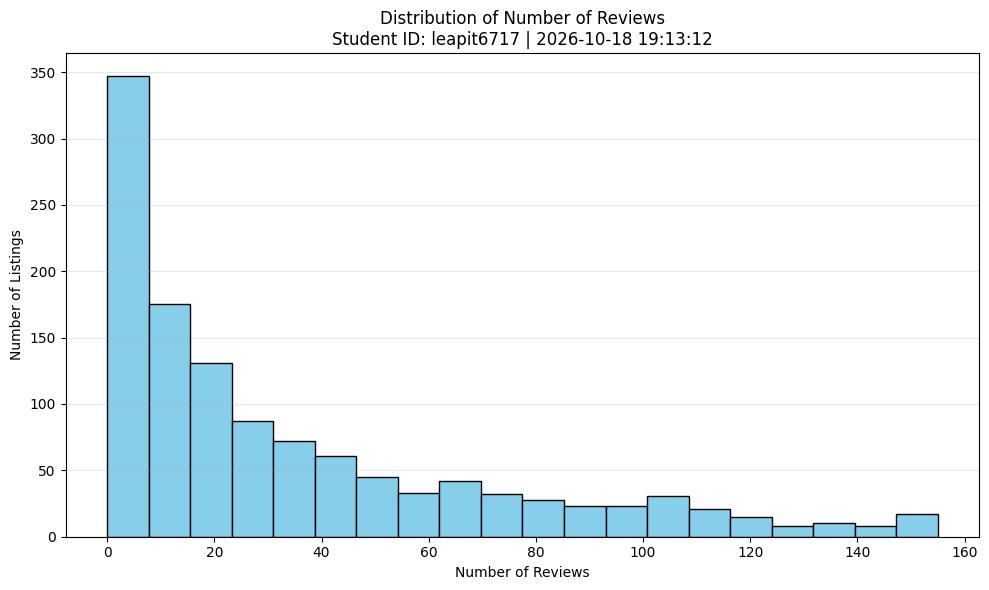

In [4]:
plt.figure(figsize=(10, 6))

plt.hist(
    df_cleaned["number_of_reviews"],
    bins=20,
    color="skyblue",
    edgecolor="black"
)

plt.title(chart_title("Distribution of Number of Reviews"))
plt.xlabel("Number of Reviews")
plt.ylabel("Number of Listings")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

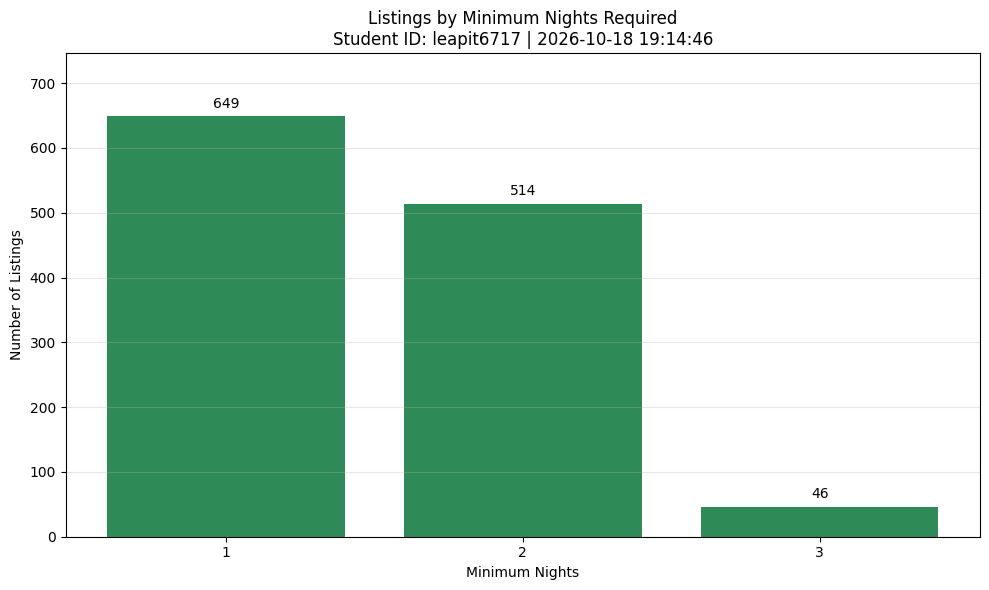

In [5]:
night_counts = (
    df_cleaned["minimum_nights"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    night_counts.index.astype(str),
    night_counts.values,
    color="seagreen"
)

plt.bar_label(bars, padding=4)

plt.title(chart_title("Listings by Minimum Nights Required"))
plt.xlabel("Minimum Nights")
plt.ylabel("Number of Listings")
plt.grid(axis="y", alpha=0.3)
plt.margins(y=0.15)

plt.tight_layout()
plt.show()

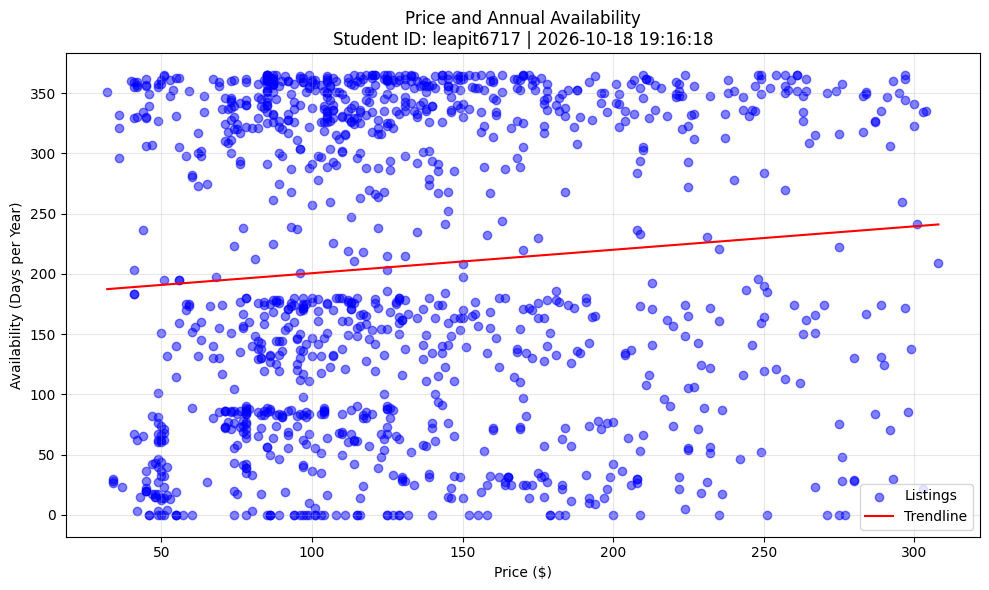

In [6]:
x = df_cleaned["price"]
y = df_cleaned["availability_365"]

slope, intercept = np.polyfit(x, y, 1)
line_x = np.linspace(x.min(), x.max(), 100)

plt.figure(figsize=(10, 6))

plt.scatter(
    x,
    y,
    color="blue",
    alpha=0.5,
    label="Listings"
)

plt.plot(
    line_x,
    slope * line_x + intercept,
    color="red",
    label="Trendline"
)

plt.title(chart_title("Price and Annual Availability"))
plt.xlabel("Price ($)")
plt.ylabel("Availability (Days per Year)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

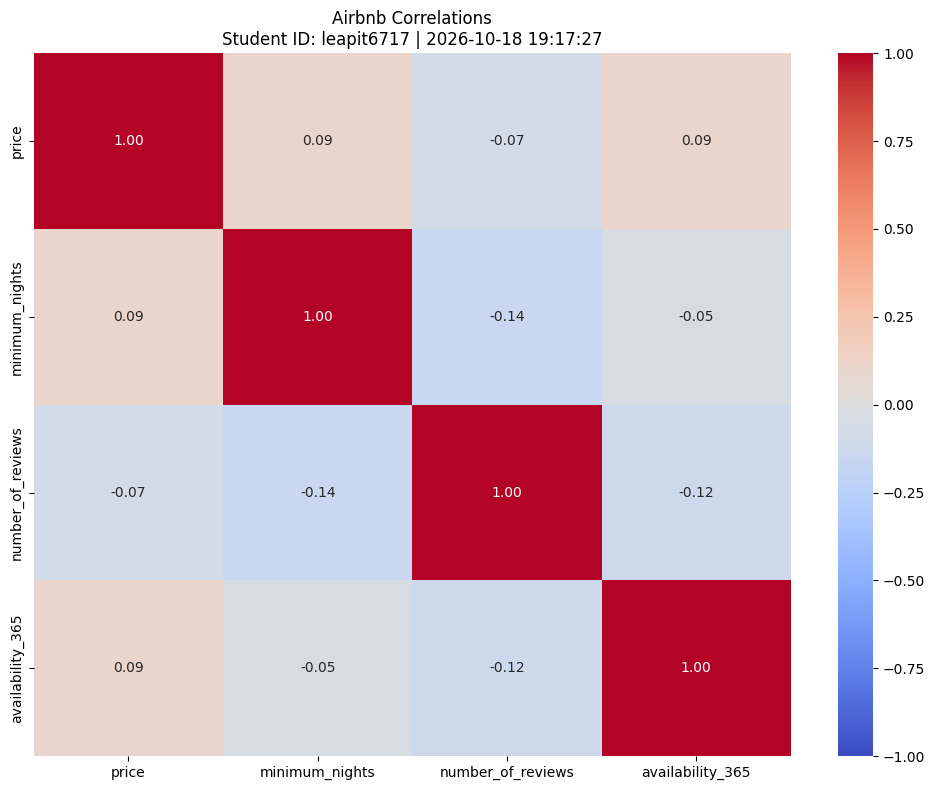

In [7]:
correlation_matrix = df_cleaned[columns].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title(chart_title("Airbnb Correlations"))

plt.tight_layout()
plt.show()